# Calibration of the selected models
Run the calibration-ready biomarker, ECG and PanEcho notebooks first. This workflow uses the selected GBDT biomarker experts, CNN-BiLSTM-Attention, and PanEcho only. Platt scaling is fit on reserved calibration predictions and evaluated on untouched test predictions. Under-supported targets remain uncalibrated. EF uses split conformal absolute residuals; the resulting interval has marginal coverage under exchangeability, not patient-specific epistemic uncertainty.

## 1. Paths, calibration utilities and artifact checks

In [5]:
from pathlib import Path
import json,math,hashlib
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss,log_loss,mean_absolute_error,mean_squared_error
from src.calibration.calibrator import PlattCalibrator
root=Path.cwd().resolve()
while not (root/'src').is_dir():
    if root.parent==root:raise FileNotFoundError('Open from ml-service')
    root=root.parent
OUT=root/'artifacts/05_calibration_fusion/selected_models/v1';OUT.mkdir(parents=True,exist_ok=True)
ART=root/'checkpoints/calibration/selected_models/v1';MIN_N=30;MIN_EACH_CLASS=10;ALPHA=.10;BOOTSTRAP_REPS=200
metrics=[];status=[]
selected_manifest={'version':1,'biomarkers':{},'ecg':{'cnn_bilstm_attention':{}},'echo':{}}
ART.mkdir(parents=True,exist_ok=True)
(ART/'manifest.json').write_text(json.dumps(selected_manifest,indent=2),encoding='utf-8')
def file_sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''):digest.update(chunk)
    return digest.hexdigest()
def read_binary(path):
    d=pd.read_csv(path);needed={'record_id','target','y_true','y_probability','base_model_sha256'}
    if not needed.issubset(d):raise ValueError(f'{path} missing {needed-set(d)}')
    if d.duplicated(['record_id','target']).any():raise ValueError(f'Duplicate identities in {path}')
    return d
def expected_calibration_error(y,p,bins=10):
    edges=np.linspace(0,1,bins+1);total=0.0
    for i in range(bins):
        mask=(p>=edges[i])&(p<edges[i+1] if i<bins-1 else p<=edges[i+1])
        if mask.any():total+=mask.mean()*abs(float(p[mask].mean())-float(y[mask].mean()))
    return float(total)
def bootstrap_ci(metric_fn,y,p,reps=BOOTSTRAP_REPS,seed=42):
    if len(y)<2:return (np.nan,np.nan)
    rng=np.random.default_rng(seed);values=[]
    for _ in range(reps):
        idx=rng.integers(0,len(y),size=len(y))
        if len(np.unique(y[idx]))<2:continue
        values.append(metric_fn(y[idx],p[idx]))
    return tuple(np.quantile(values,[.025,.975])) if values else (np.nan,np.nan)
def calibrate(cal,test,modality,target,path,base_model_path,manifest_bucket,force_uncalibrated=False):
    a=cal[cal.target==target].copy();b=test[test.target==target].copy()
    if a.empty or b.empty:raise ValueError(f'Missing {modality}/{target}')
    if set(a.record_id.astype(str))&set(b.record_id.astype(str)):raise ValueError('Calibration/test identity overlap')
    if not base_model_path.is_file():raise FileNotFoundError(f'Matching base model missing: {base_model_path}')
    model_hash=file_sha256(base_model_path)
    observed_hashes=set(a.base_model_sha256.astype(str))|set(b.base_model_sha256.astype(str))
    if observed_hashes!={model_hash}:raise ValueError(f'Prediction/model hash mismatch for {modality}/{target}')
    y=a.y_true.to_numpy(int);p=a.y_probability.to_numpy(float)
    yt=b.y_true.to_numpy(int);pt=np.clip(b.y_probability.to_numpy(float),1e-6,1-1e-6)
    if not np.isfinite(p).all() or not np.isfinite(pt).all() or not set(np.unique(y)).issubset({0,1}) or not set(np.unique(yt)).issubset({0,1}):
        raise ValueError(f'Invalid binary predictions for {modality}/{target}')
    counts=pd.Series(y).value_counts().to_dict();supported=len(y)>=MIN_N and counts.get(0,0)>=MIN_EACH_CLASS and counts.get(1,0)>=MIN_EACH_CLASS
    ok=supported and not force_uncalibrated
    pc=pt.copy();state='uncalibrated: insufficient class support'
    if force_uncalibrated:state='uncalibrated: small UCI cohort; no Platt artifact is created'
    if ok:
        model=PlattCalibrator().fit(p,y);pc=np.clip(model.predict_proba(pt),1e-6,1-1e-6)
        path.parent.mkdir(parents=True,exist_ok=True);model.save(path);state='platt'
        manifest_bucket[target]={'status':'platt','artifact':path.relative_to(root/'checkpoints/calibration').as_posix(),'base_model_sha256':model_hash}
    def score_row(prefix,values):
        row={f'{prefix}_brier':brier_score_loss(yt,values),f'{prefix}_log_loss':log_loss(yt,values,labels=[0,1]),f'{prefix}_ece':expected_calibration_error(yt,values)}
        for metric,fn in [('brier',brier_score_loss),('log_loss',lambda yy,pp:log_loss(yy,pp,labels=[0,1])),('ece',expected_calibration_error)]:
            lo,hi=bootstrap_ci(fn,yt,values);row[f'{prefix}_{metric}_ci_lower']=float(lo);row[f'{prefix}_{metric}_ci_upper']=float(hi)
        return row
    row={'modality':modality,'target':target,'calibration_n':len(y),'negative':counts.get(0,0),'positive':counts.get(1,0),
         'status':state,'test_n':len(yt),**score_row('raw',pt)}
    if ok:row.update(score_row('calibrated',pc))
    else:row.update({f'calibrated_{name}':np.nan for name in ['brier','log_loss','ece']})
    if not ok:
        for name in ['brier','log_loss','ece']:
            row[f'calibrated_{name}_ci_lower']=np.nan;row[f'calibrated_{name}_ci_upper']=np.nan
    fig,ax=plt.subplots(figsize=(5,5))
    for values,label in [(pt,'raw'),(pc,'Platt' if ok else 'raw; uncalibrated')]:
        obs,pred=calibration_curve(yt,values,n_bins=min(10,max(2,len(yt)//10)),strategy='quantile')
        ax.plot(pred,obs,marker='o',label=label)
    ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Mean predicted probability',ylabel='Observed fraction',title=f'{modality}: {target}')
    ax.legend();fig.tight_layout();fig.savefig(OUT/f'{modality}_{target}_reliability.png',dpi=160);plt.show();plt.close(fig)
    metrics.append(row);status.append({'modality':modality,'target':target,'status':state,'artifact':path.relative_to(root/'checkpoints/calibration').as_posix() if ok else None})


## 2. Fit four independent biomarker experts

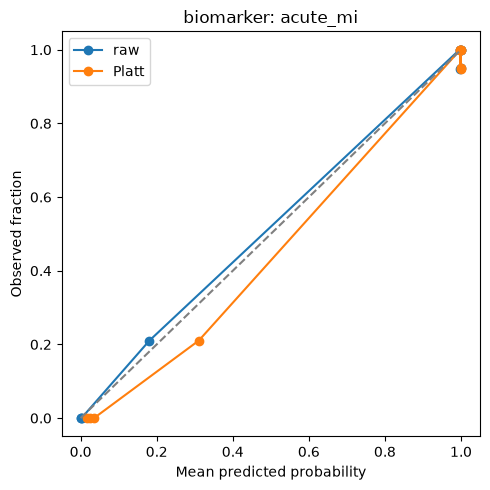

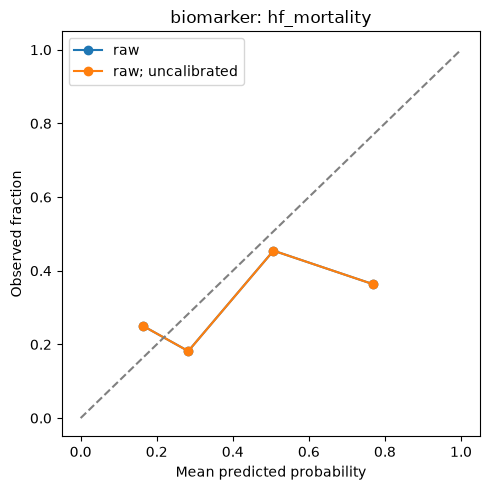

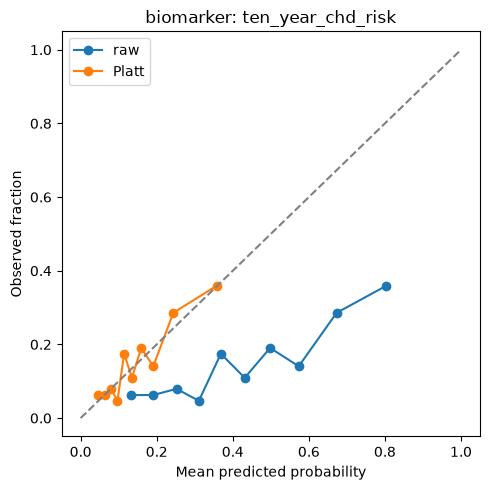

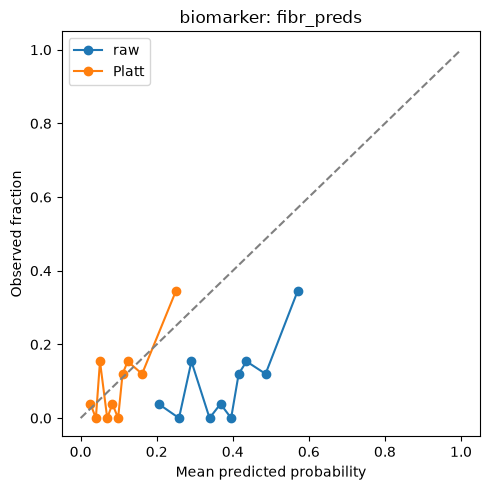

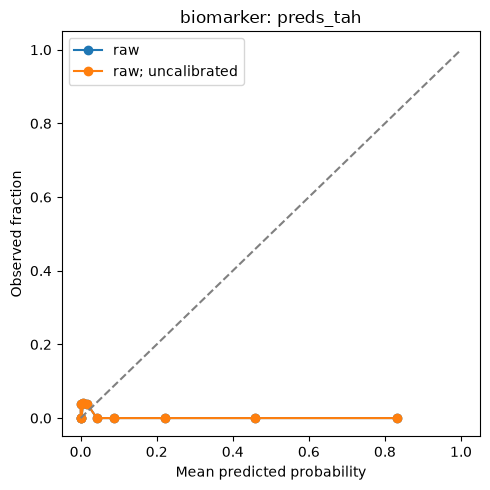

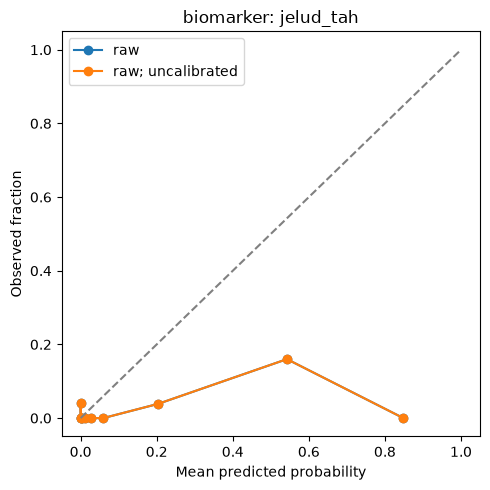

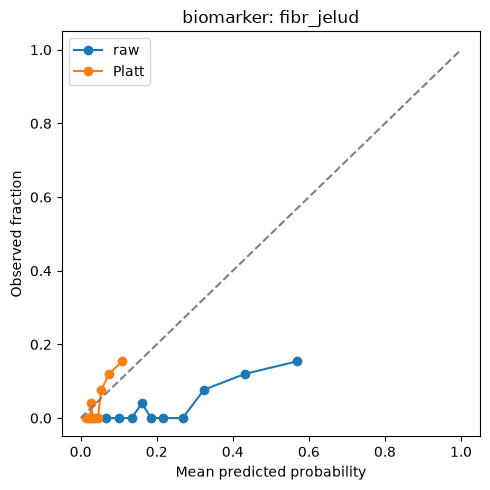

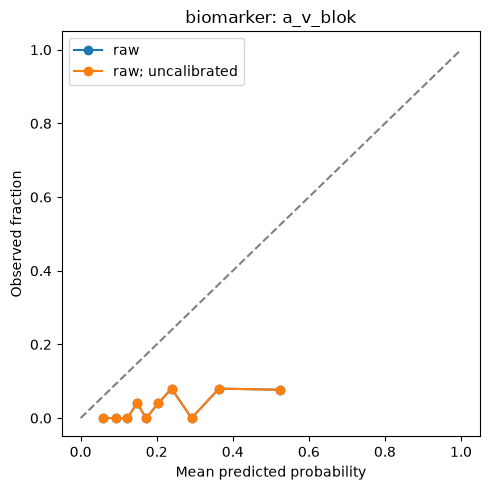

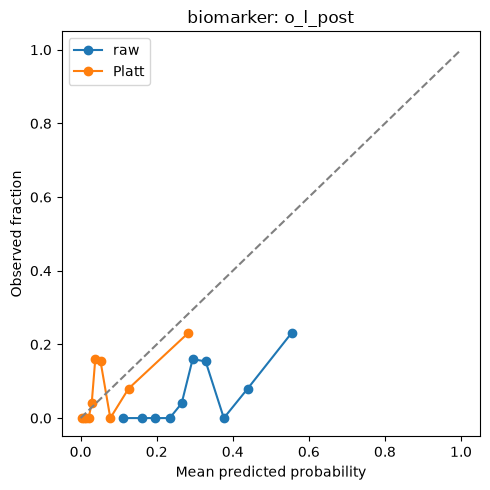

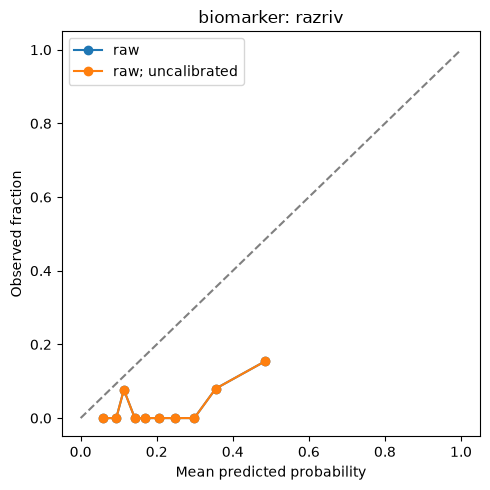

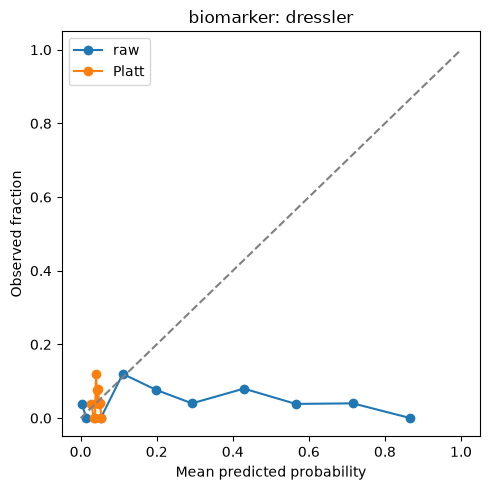

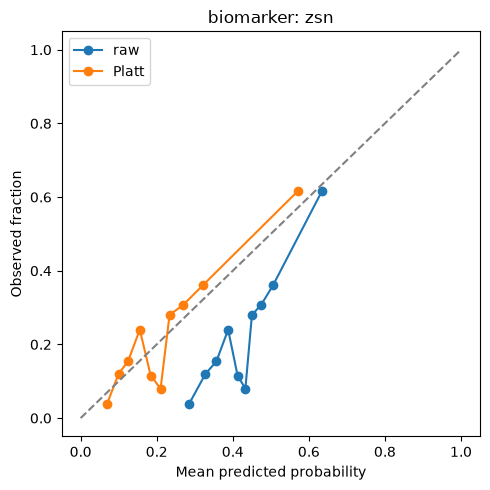

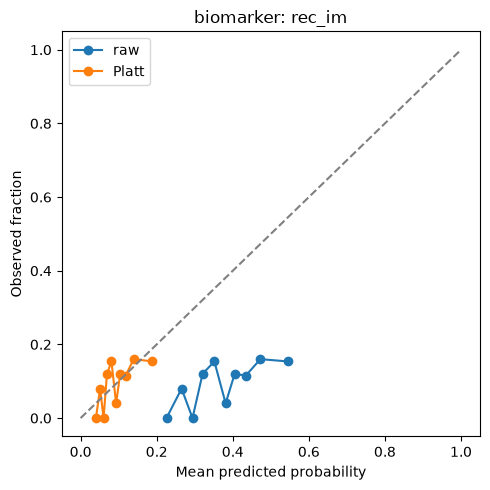

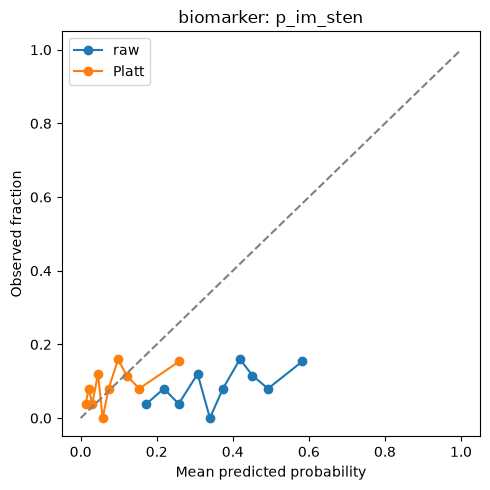

In [6]:
bio=root/'artifacts/03_training/biomarkers/selected_gbdt_stacking/v1'
targets={'zheen':['acute_mi'],'uci_heart_failure':['hf_mortality'],'framingham':['ten_year_chd_risk'],
         'mi_complications':['fibr_preds','preds_tah','jelud_tah','fibr_jelud','a_v_blok','o_l_post','otec_lanc','razriv','dressler','zsn','rec_im','p_im_sten']}
for dataset,names in targets.items():
    folder=bio/dataset;cal_path=folder/'validation_predictions.csv';test_path=folder/'test_predictions.csv'
    if not cal_path.exists() or not test_path.exists():print('[Skipped]',dataset,'training output missing');continue
    cal=read_binary(cal_path);test=read_binary(test_path)
    split_manifest=pd.read_csv(bio/'split_manifest.csv')
    selected_manifest['biomarkers'].setdefault(dataset,{})
    for target in names:
        if target not in set(cal.target):continue
        sub=split_manifest[(split_manifest.dataset==dataset)&(split_manifest.target==target)]
        cids=set(sub.loc[sub.split=='calibration','record_id'].astype(str))
        tids=set(sub.loc[sub.split=='test','record_id'].astype(str))
        if set(cal.loc[cal.target==target,'record_id'].astype(str))!=cids or set(test.loc[test.target==target,'record_id'].astype(str))!=tids:
            raise ValueError(f'Split manifest mismatch: {dataset}/{target}')
        base=root/'checkpoints/biomarkers'/dataset/target/'selected_gbdt_stacking'/'v1'/'model.joblib'
        calibrate(cal,test,'biomarker',target,ART/'biomarkers'/dataset/'selected_gbdt_stacking'/f'{target}.pkl',base,
          selected_manifest['biomarkers'][dataset],force_uncalibrated=(dataset=='uci_heart_failure' and target=='hf_mortality'))

## 3. Fit one ECG calibrator per diagnostic and rhythm label

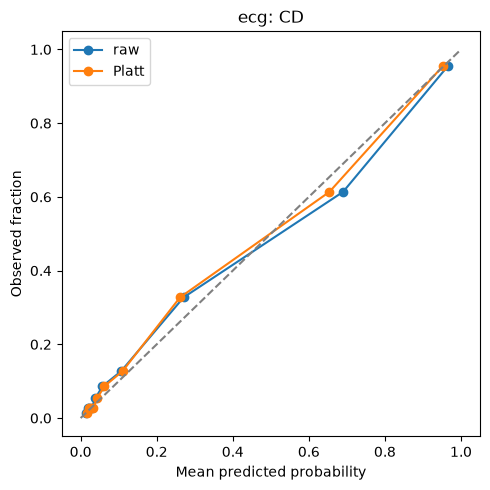

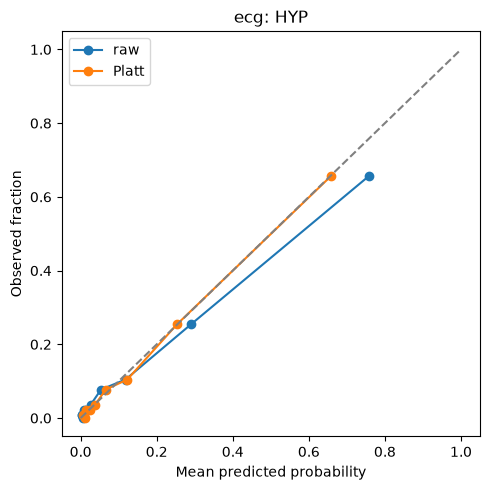

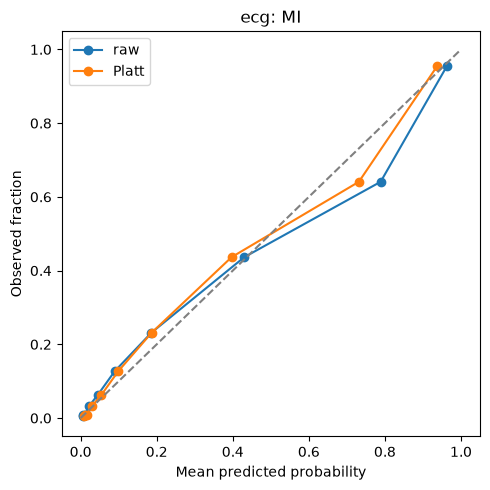

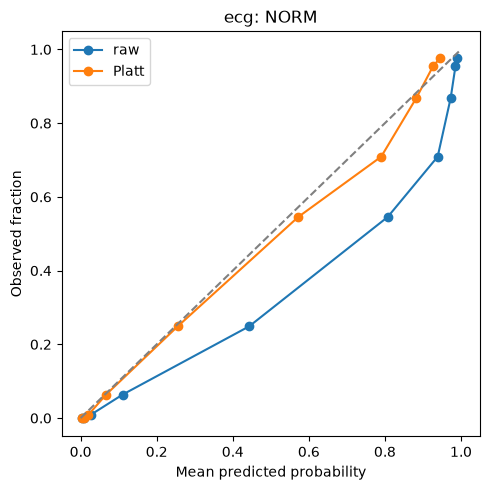

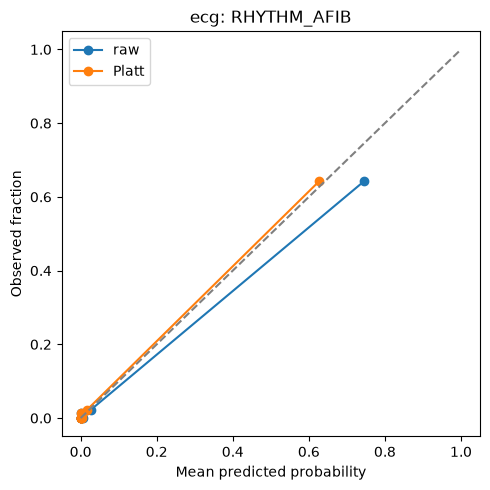

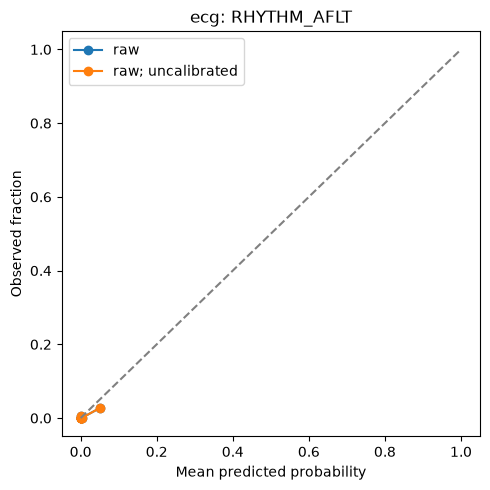

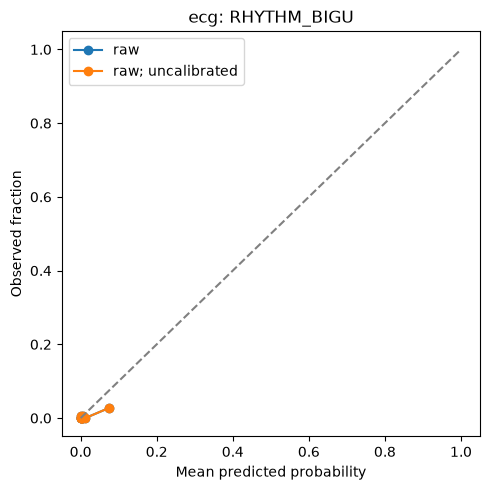

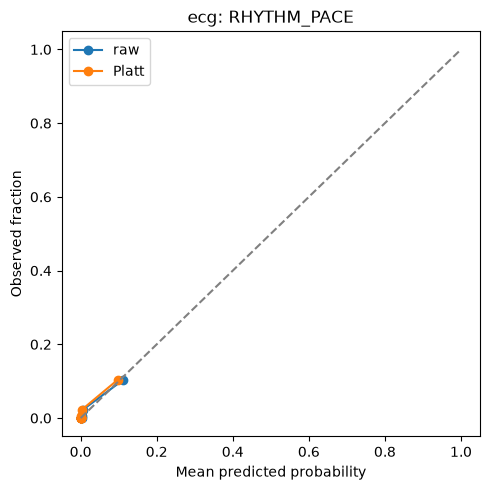

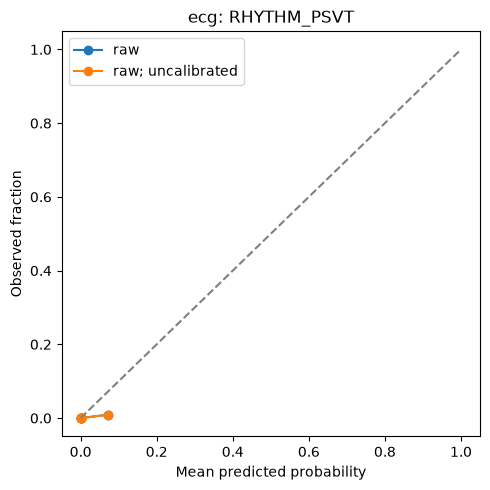

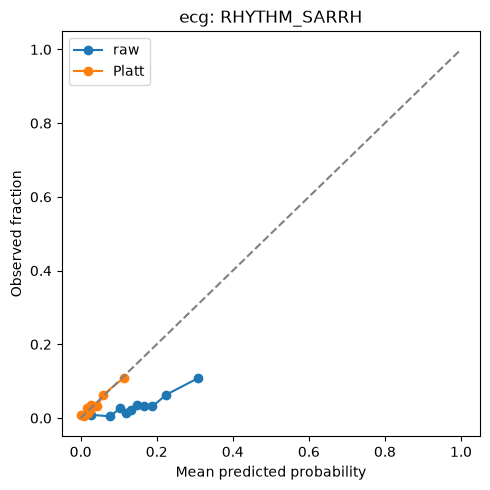

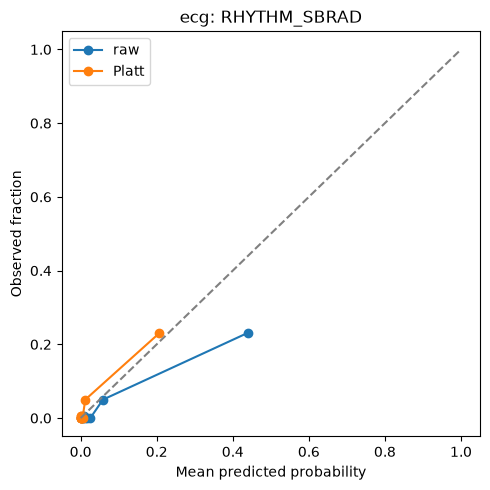

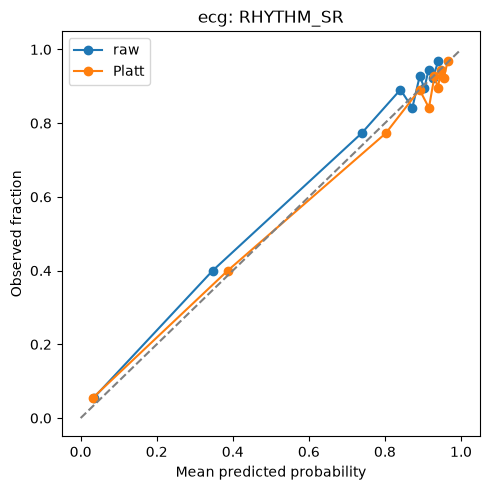

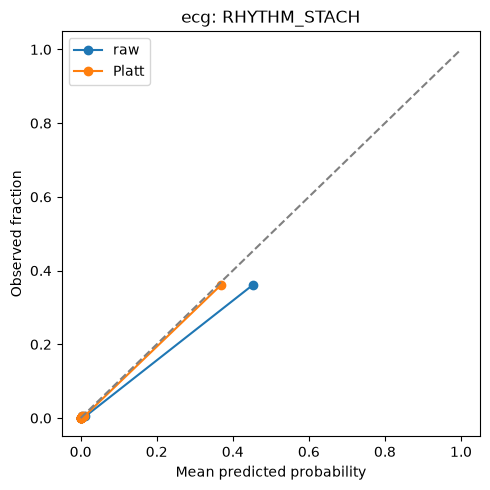

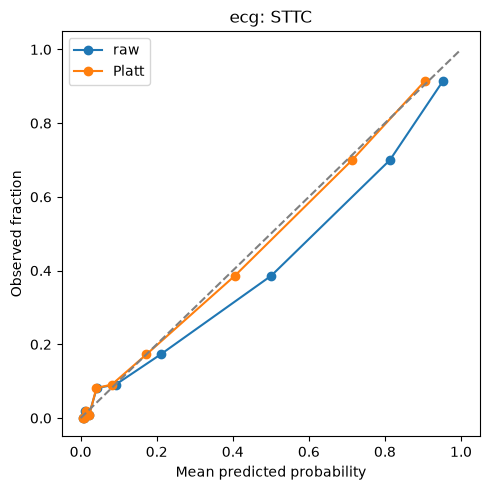

In [7]:
ecg_dir=root/'artifacts/03_training/ecg/ptbxl/selected_cnn_bilstm/v1'
if (ecg_dir/'validation_predictions.csv').exists() and (ecg_dir/'test_predictions.csv').exists():
    cal=read_binary(ecg_dir/'validation_predictions.csv');test=read_binary(ecg_dir/'test_predictions.csv')
    split_manifest=pd.read_csv(ecg_dir/'split_manifest.csv')
    checkpoint=root/'checkpoints/ecg/ptbxl/selected_cnn_bilstm/v1/model.pt'
    for target in sorted(cal.target.unique()):
        cids=set(split_manifest.loc[split_manifest.split=='calibration','ecg_id'].astype(str))
        tids=set(split_manifest.loc[split_manifest.split=='test','ecg_id'].astype(str))
        if set(cal.loc[cal.target==target,'record_id'].astype(str))!=cids or set(test.loc[test.target==target,'record_id'].astype(str))!=tids:
            raise ValueError(f'ECG split manifest mismatch: {target}')
        calibrate(cal,test,'ecg',target,ART/'ecg'/'ptbxl'/'selected_cnn_bilstm'/f'{target}.pkl',checkpoint,
          selected_manifest['ecg']['cnn_bilstm_attention'])
else:print('[Skipped] ECG training output missing')

## 4. PanEcho EF split conformal interval (90% nominal coverage)

In [8]:
echo=root/'artifacts/03_training/echo/echonet/selected_panecho/v1'
cp,tp=echo/'validation_predictions.csv',echo/'test_predictions.csv'
if cp.exists() and tp.exists():
    cal=pd.read_csv(cp);test=pd.read_csv(tp);split_manifest=pd.read_csv(echo/'split_manifest.csv')
    if cal.video_path.duplicated().any() or test.video_path.duplicated().any():raise ValueError('Duplicate video IDs')
    if set(cal.video_path.astype(str))&set(test.video_path.astype(str)):raise ValueError('Calibration/test overlap')
    if set(cal.video_path.astype(str))!=set(split_manifest.loc[split_manifest.split=='calibration','video_path'].astype(str)):raise ValueError('Echo calibration manifest mismatch')
    if set(test.video_path.astype(str))!=set(split_manifest.loc[split_manifest.split=='test','video_path'].astype(str)):raise ValueError('Echo test manifest mismatch')
    checkpoint=root/'checkpoints/echo/echonet/selected_panecho/v1/model.pt'
    if not checkpoint.is_file():raise FileNotFoundError(f'Matching fine-tuned PanEcho checkpoint missing: {checkpoint}')
    model_hash=file_sha256(checkpoint)
    observed_hashes=set(cal.base_model_sha256.astype(str))|set(test.base_model_sha256.astype(str))
    if observed_hashes!={model_hash}:raise ValueError('Echo predictions/checkpoint hash mismatch')
    residual=np.abs(cal.EF_true.to_numpy(float)-cal.EF_pred.to_numpy(float));n=len(residual)
    if n==0 or not np.isfinite(residual).all():raise ValueError('Invalid or empty EF calibration residuals')
    k=int(math.ceil((n+1)*(1-ALPHA)))
    if k>n:raise ValueError(f'Insufficient calibration records for finite quantile: n={n}, k={k}')
    q=float(np.partition(residual,k-1)[k-1])
    record={'method':'split_conformal_absolute_residual','alpha':ALPHA,'nominal_coverage':1-ALPHA,
      'n_calibration':n,'order_statistic_index_1_based':k,'absolute_error_quantile':q,
      'assumption':'Marginal coverage under exchangeability; not conditional or patient-specific uncertainty.'}
    dest=ART/'echo'/'echonet'/'selected_panecho'/'ef_absolute_error_quantile.json';dest.parent.mkdir(parents=True,exist_ok=True)
    dest.write_text(json.dumps(record,indent=2),encoding='utf-8')
    selected_manifest['echo']['panecho_echonet_finetuned']={'EF':{'status':'split_conformal','artifact':dest.relative_to(root/'checkpoints/calibration').as_posix(),'base_model_sha256':model_hash}}
    y=test.EF_true.to_numpy(float);pred=test.EF_pred.to_numpy(float)
    lo=np.clip(pred-q,0,100);hi=np.clip(pred+q,0,100)
    metrics.append({'modality':'echo','target':'EF','status':'90% split conformal','calibration_n':n,'test_n':len(y),
      'test_coverage':float(((y>=lo)&(y<=hi)).mean()),'mean_interval_width':float((hi-lo).mean()),
      'test_mae':float(mean_absolute_error(y,pred)),'test_rmse':float(mean_squared_error(y,pred)**.5),'quantile':q})
    pd.DataFrame({'video_path':test.video_path,'EF_true':y,'EF_pred':pred,'lower_90':lo,'upper_90':hi}).to_csv(OUT/'echo_test_prediction_intervals.csv',index=False)
else:print('[Skipped] PanEcho output missing')

## 5. Final independent test metrics, artifacts and report

In [9]:
table=pd.DataFrame(metrics);table.to_csv(OUT/'selected_model_calibration_test_metrics.csv',index=False)
(OUT/'calibration_artifact_status.json').write_text(json.dumps(status,indent=2),encoding='utf-8')
(ART/'manifest.json').write_text(json.dumps(selected_manifest,indent=2),encoding='utf-8')
(OUT/'calibration_report.md').write_text('# Selected-model calibration report\n\nCalibration fit uses reserved validation predictions only. Metrics and bootstrap intervals use untouched test predictions. Under-supported binary targets remain uncalibrated; the small UCI heart-failure cohort is intentionally left uncalibrated. EF conformal intervals target marginal coverage under exchangeability, not conditional or patient-specific coverage. Calibration artifacts are tied to the SHA-256 of the exact model checkpoint.\n\n'+table.to_string(index=False),encoding='utf-8')
display(table);print('Saved report under',OUT);print('Saved matching-artifact manifest under',ART)

,modality,target,calibration_n,negative,positive,status,test_n,raw_brier,raw_log_loss,raw_ece,...,calibrated_brier_ci_upper,calibrated_log_loss_ci_lower,calibrated_log_loss_ci_upper,calibrated_ece_ci_lower,calibrated_ece_ci_upper,test_coverage,mean_interval_width,test_mae,test_rmse,quantile
0,biomarker,acute_mi,198,76.0,122.0,platt,198,0.013725,0.082988,0.015254,...,0.028499,0.020877,0.208417,0.018436,0.046043,NaN,NaN,NaN,NaN,NaN
1,biomarker,hf_mortality,45,30.0,15.0,uncalibrated: small UCI cohort; no Platt artif...,45,0.252050,0.766701,0.263782,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,biomarker,ten_year_chd_risk,636,539.0,97.0,platt,636,0.206811,0.601990,0.272262,...,0.132658,0.346398,0.430686,0.015731,0.049486,NaN,NaN,NaN,NaN,NaN
3,biomarker,fibr_preds,255,229.0,26.0,platt,255,0.159704,0.502452,0.278524,...,0.102443,0.217909,0.353787,0.016952,0.061457,NaN,NaN,NaN,NaN,NaN
4,biomarker,preds_tah,255,252.0,3.0,uncalibrated: insufficient class support,255,0.111662,0.417425,0.156156,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,biomarker,jelud_tah,255,248.0,7.0,uncalibrated: insufficient class support,255,0.112277,0.393564,0.147125,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,biomarker,fibr_jelud,255,244.0,11.0,platt,255,0.088768,0.319066,0.206847,...,0.055163,0.087771,0.205502,0.002653,0.029550,NaN,NaN,NaN,NaN,NaN
7,biomarker,a_v_blok,255,246.0,9.0,uncalibrated: insufficient class support,255,0.078295,0.293560,0.190665,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,biomarker,o_l_post,253,237.0,16.0,platt,254,0.116422,0.396176,0.230008,...,0.086466,0.151561,0.293725,0.019495,0.065660,NaN,NaN,NaN,NaN,NaN
9,biomarker,razriv,255,247.0,8.0,uncalibrated: insufficient class support,255,0.072155,0.281472,0.185707,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saved report under D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\artifacts\05_calibration_fusion\selected_models\v1
Saved matching-artifact manifest under D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\calibration\selected_models\v1
